In [1]:
import pandas as pd
import numpy as np
import glob
import os.path

import astropy.time as astro_time
import astropy.timeseries as timeseries
import astropy.units as u
import matplotlib.pyplot as plt
import scipy

import astropy.stats
from scipy.optimize import curve_fit


from matplotlib.ticker import MaxNLocator

from multiprocessing import cpu_count
import pathos
from phasedm import pdm, beta_test


## Globals
n_sigma_conf = {1: 68.27/100, 2: 95.45/100, 3: 99.73/100, 4: 99.9937/100}


In [2]:
#def get_values(series):
#	return list(map(lambda t: t.value, series))

def get_time_values(ts, time_format):
    """
    Time format must match values
    set in Time or TimeDelta depending on use.
    """
    return list(map(lambda t: t.to_value(time_format), ts))

def read_necessary_columns(file_name, target_id = "T1", sep = "\t"):
    data = pd.read_csv(file_name, sep = sep)

    #print(data.keys())

    #print(data.keys())

    data = data[[
        "J.D.-2400000",
        "AIRMASS",
        "EXPTIME",
        "FWHM_Mean",
        "rel_flux_"+target_id,
        "rel_flux_err_"+target_id,
        "rel_flux_SNR_"+target_id,
        "Source-Sky_"+target_id,
        #"N_Src_Pixels_"+target_id,
        "Source_Error_"+target_id,
        "Source_SNR_"+target_id,
        # "Peak_"+target_id,
        "Mean_"+target_id,
        "Sky/Pixel_"+target_id,
        #"N_Sky_Pixels_"+target_id,
        "FWHM_"+target_id,
        "Width_"+target_id,
        "X-Width_"+target_id,
        "Y-Width_"+target_id,
        "Angle_"+target_id,
        "Roundness_"+target_id
        ]]

    #print(f"Accessed keys for {file_name}")

    return data


def process_file(file_name, samples_per_peak = 5):
    file_errors = []
    target_id_list = ["T1", "C1"]
    target_id = ""

    found_separator = False

    data = []
    for target in ["T1", "C1"]:
        for sep in ["\t", ",", "\t\t"]:
            try: 
                data = read_necessary_columns(file_name, target_id = target,
                                              sep = "\t")
                target_id = target
                found_separator = True
    #            print(f"Separator was {repr(sep)}.")
                break
            except Exception as e:
                # try:
                #     data = read_necessary_columns(file_name, sep = ",")
                #     target_id = target
                #     break
                # except Exception as e2:
                #     file_errors.append(e2)
                file_errors.append(e)

        if found_separator:
            break
    else:
        if target_id == "":
            raise Exception(f"Target id not in list: {target_id_list}")
        else:
            assert len(data) != 0, "File error but there was still data"
            # No `continue` statements were procesed so
            # file is unexpected / malformed
            raise Exception(file_errors)

    #exit()
    time = data["J.D.-2400000"].to_numpy()
    #mean_interval = np.median(np.diff(time))

    time = astro_time.Time(time, format = "mjd")

    #ts_data = {name: np.concatenate([zero_data, data[name]]) for name in data.keys()}
    ts_data = {name: data[name] for name in data.keys()}
    ts = timeseries.TimeSeries(time = time, data = ts_data)

    #ts = ts.fold(period = 90*u.s)


    #flux_names = ["Mean_"+target_id, "Source_Error_"+target_id]
    #fluxes = [ts[name] for name in flux_names]

    #flux_name = "Mean_"+target_id
    prefix = "rel_flux"
    #prefix = "Mean"
    flux_name = prefix+"_"+target_id
    flux = ts[flux_name]
    
    err_flux = ts["rel_flux_err_"+target_id] 
    if "mean" in prefix.lower():
        err_flux = err_flux * flux.mean()

    ls = timeseries.LombScargle(ts["time"], flux,
                                dy = err_flux)
    # Want to remove frequency associated with the sampling frequency



    sampling_delta = abs(ts["time"][1] - ts["time"][0])
    #print(f"{sampling_delta = }")
    sampling_frequency = 1/sampling_delta

    ls = remove_freq_signal(ls, 1/sampling_delta)




    (freq, power) = non_aliased_power_spectrum(ls, sampling_frequency,
                                               samples_per_peak = samples_per_peak)


    nyquist_frequency = 0.5*sampling_frequency 
    max_freq = 5 * nyquist_frequency
    # Cut off below the sampling frequency to do with aliasing

    freq_idx = np.abs(freq - nyquist_frequency).argmin() # Property of periodogram is that it is symmetric

    #print(f"{freq_idx = }")
    freq = freq[:freq_idx]
    #print(f"{freq.max() = }")
    power = power[:freq_idx]

    return [ts, [freq, power], ls, target_id]



def plot_rows_columns(file_name_list: list[str],
                      results_list,
                      rows = "all",
                      columns = "all",
                      ax_list = [],
                      bins = "blocks",
                      xticks = 5,
                      yticks = 5,
                      n_bootstraps = 1000,
                      double_bootstrap = False):
    """
    Rows accepts either "all" to plot all results
    or part of a filename associated with measurement files.

    Column accepts the following:
    `["all", "signal", "periodogram", "false-alarm", "pvalue"]`

    Bins is number of histogram bins, or method such as Bayesian blocks (`"blocks"`)

    xticks is number of ticks to display on x-axis
    yticks is number of ticks to display on y-axis

    NOTE: `ax_list` assumes all axes come from the same figure
    """
    assert type(columns[0]) == str, f"Column or first element of columns is not str: {columns = }"
    # Python short circuits boolean operators

    assert type(columns[0]) == str, f"Column or first element of columns is not str: {columns = }"
    #assert (type(rows) == str) or len(list(filter(lambda x: type(x) != int, rows))) == 0, f"Rows is not a valid argument: {rows = }"


    n_plots = len(results_list)
    assert n_plots != 0, "Results list is empty for plotting"

    if type(rows) == str:
        assert rows == "all", f"Only `str` value for rows is `all`. Did you mean a list? {rows  = }"
    elif type(rows) == list:
        all_text = "\t".join(rows)
        for row in rows:
            assert row in all_text, f"Row value `{row}` not found in processed files: {file_name_list = }"


    allowed_columns = ["signal", "periodogram", "false-alarm", "pvalue"]
    if type(columns) == str:
        assert columns == "all", f"Only `str` value for column is `all`. Did you mean a list? {columns = }"
    elif type(columns) == list:
        for column in columns:
            assert column in allowed_columns, f"Column value `{column}` is not allowed. The options for column are {allowed_columns}"

    if type(rows) == list:
        rows = list(filter(lambda s: s != "all", rows))
        if len(rows) == 0:
            return # Nothing to plot

    if type(columns) == list:
        columns  = list(filter(lambda s: s != "all", columns))
        if len(columns) == 0:
            return # Nothing to plot





    if rows == "all":
        rows = list(range(n_plots))
    if columns == "all":
        columns = ["signal", "periodogram", "false-alarm", "pvalue"]


    n_rows, n_column = len(rows), len(columns)
    #print(f"{n_rows = }, {n_column = }")
    if len(ax_list) == 0:
        fig, ax_list = plt.subplots(nrows = n_rows, ncols = n_column,
                                    figsize = (16, 8))
    else:
        fig = plt.gcf()


    # Iterating over multiple axes so needs to be a list
    if n_rows == 1:
        ax_list = [ax_list]



    long_cache = {obj_name: None for obj_name in rows}

    for (row_idx, axis) in enumerate(ax_list, start = 0):
        row_name = rows[row_idx]
        if not (row_name in rows):
            print(f"skipping {row_name = }")
            continue

        # Single column idx will always be 0
        if n_column == 1:
            axis = [axis]
        ts, (freq,power), ls, target_id = results_list[row_idx]


        cache = {column_name: None for column_name in allowed_columns}

        # TODO: CACHE RESULTS!
        for (column_idx, column) in enumerate(columns, start = 0):
            if column == "signal":
                if cache[column] is None:
                    time = get_time_values(ls.t, time_format = "mjd")
                    flux = ts["rel_flux_"+target_id]
                    if True:#if (ls.dy is None) or (len(ls.dy) == 0):
                        err_flux = ts["rel_flux_err_"+target_id]
                    else:
                        err_flux = ls.dy
                        #print(f"{err_flux = }")

                    cache[column] = (time, flux, err_flux)
                else:
                    time, flux, err_flux = cache[column]

                axis[column_idx].errorbar(time, flux, yerr = err_flux, fmt = "x")

            elif column == "periodogram":
                BAYESIAN = True
                if cache[column] is None:
                    if BAYESIAN:
                        power = np.exp(power)
                    else:
                        power = power
                    cache[column] = (freq, power)
                else:
                    freq, power = cache[column]

                # # NOTE: Bayesian is *strictly* only for a *pure* sine wave
                # power = np.exp(power)
                USE_PERIOD = True

                if USE_PERIOD:
                    period = 1/freq
                    axis[column_idx].plot(period, power)

                    axis[column_idx].set_xscale("log")
                    # axis[column_idx].set_yscale("log")

                    axis[column_idx].set_xlabel("Period [days] (log scale)")
                else:
                    axis[column_idx].plot(freq, power)

                    axis[column_idx].set_xscale("log")
                    # axis[column_idx].set_yscale("log")

                    axis[column_idx].set_xlabel("Frequency [1/day] (log scale)")

                axis[column_idx].set_title("Lomb-Scargle Periodogram")

            # elif column == "false-alarm":
            #     if cache[column] is None:
            #         (data_fap_value, lower_conf, upper_conf) = process_false_alarm(ls, power, n_bootstraps=n_bootstraps, double_bootstrap = double_bootstrap)
            #         cache[column] = FAP_list
            #     else:
            #         FAP_list = cache[column]
            #
            #     if len(FAP_list) != 0:
            #         print(f"{FAP_list.mean() = }")
            #         hist, bin_edges = astropy.stats.histogram(FAP_list, bins = bins)
            #         axis[column_idx].stairs(hist, bin_edges)
            #     else:
            #         print("WARNING false-alarm list is EMPTY")
            #
            #     axis[column_idx].set_title("False Alarm Probability")
            #
            # elif column == "pvalue":
            #     # Need to compute pvalue for false-alarm so combine both
            #
            #     if cache[column] is None:
            #         if cache["false-alarm"] is None:
            #             FAP_list = process_false_alarm(ls, power, n_bootstraps=n_bootstraps, double_bootstrap = double_bootstrap)
            #             cache["false-alarm"] = FAP_list
            #         else:
            #             FAP_list = cache["false-alarm"]
            #
            #         #"rel_flux_SNR_T1",
            #         #"Source_SNR_T1",
            #         snr = np.median(ts["Source_SNR_"+target_id])
            #         if len(FAP_list) != 0:
            #             pvalue, pvalue_list = calculate_probability(snr, FAP_list, p_thresh = 0.05, conf_level = 99.7/100)
            #         else:
            #             print("WARNING false-alarm list is EMPTY")
            #             pvalue, pvalue_list = (0, [])
            #
            #         cache[column] = (pvalue, pvalue_list, snr)
            #
            #     else:
            #         pvalue, pvalue_list, snr = cache[column]
            #
            #
            #     if len(pvalue_list) != 0:
            #         print(f"{pvalue = }; {pvalue_list.mean() = }")
            #         hist, bin_edges = astropy.stats.histogram(pvalue_list, bins = bins)
            #         axis[column_idx].stairs(hist, bin_edges)
            #     else:
            #         print("WARNING pvalue list is EMPTY")
            #
            #     axis[column_idx].set_title("Probability that Peak is Produced by Noise")
            #
            #
            # Set title of plot
            if column_idx == 0:
                curr_title = axis[column_idx].get_title()
                filename = os.path.basename(file_name_list[row_idx])
                axis[column_idx].set_title(filename + "\n" + curr_title)

        for subplot in axis:
            subplot.xaxis.set_major_locator(MaxNLocator(xticks))
            subplot.yaxis.set_major_locator(MaxNLocator(yticks))
        #     plt.setp(subplot.get_xticklabels(), rotation=30, ha='right')

        long_cache[row_name] = (cache, ts, ls, target_id)
    fig.tight_layout()

    return fig, ax_list, long_cache


In [3]:
def remove_max_power_freq(ls, freq, power, n = 1, n_bootstraps = 1000, double_bootstrap = False, snr = None, conf_level = 99.7/100, fap_threshold = 1e-4):
    """MODIFIES LOMBSCARGLE INSTANCE

    Remove the frequency associated with the nth current highest powers
    """
    if n < 1:
        return ls, (freq, power), []

    removed_values = [] # (freq, power)
    for i in range(1, n+1):
        max_power = power.max()

        power_freq = freq[power == max_power][-1]

        (data_fap_value, lower_conf, upper_conf, std_err), fap_list  = process_false_alarm(ls, power, n_bootstraps = n_bootstraps, double_bootstrap = double_bootstrap)
        #print(f"{np.mean(fap_list) = } {np.median(fap_list) = }")
        # Convert false-alarm to pvalue with confidence
        if snr is None:
            snr = (1/ls.dy).mean() # TODO: Really not sure about this...
            #snr = 100

        #print(f"median {snr = }")
        #print(f"{fap_list = }")

        pvalue, prob_peak_list = calculate_probability(snr, fap_list, fap_threshold)

        #print(f"{data_fap_value = }; {pvalue = }"
        threshold = 1 - conf_level
        if pvalue > threshold:
            # halt
            print(f"Halted at {i = } {power_freq = } (Not removed). False-alarm was too high: {data_fap_value*100} +/- {std_err*100}% [{lower_conf*100}, {upper_conf*100}]%; {pvalue = }\n\n")
            #print(f"{fap_list = }\n{prob_peak_list = }")
            break
        else:
            pass
            #print(f"{pvalue = }{threshold =}")

        ls = remove_freq_signal(ls, power_freq)
        removed_values.append((power_freq, max_power, (data_fap_value, lower_conf, upper_conf, pvalue)))

        freq, power = non_aliased_power_spectrum(ls, max_freq = freq.max())
    return ls, (freq, power), removed_values


def remove_freq_signal(ls, freq):
    """MODIFIES LOMBSCARGLE INSTANCE"""
    # Make sure to not modify original values yet
    #time = np.array(ls.t)
    time = ls.t
    #print(time)
    flux = np.array(ls.y)
    #errors = np.array(ls.dy)

    # try:
    #     print(f"{freq = }")
    #     freq = freq.tolist()
    # except:
    #     pass

    #print(f"{freq = }; {freq.ndim = }")
    sampling_model = ls.model(time, frequency = freq)


    ls.y = flux - sampling_model
    #ls = timeseries.LombScargle(time, ls.y)
    return ls # Not needed but just for sanity


In [4]:
def make_power_spectrum(ls, max_freq, samples_per_peak = 5):
    return ls.autopower(method = "fast", maximum_frequency = max_freq, # Nyquist factor (at least 2)
                        samples_per_peak = samples_per_peak)

def non_aliased_power_spectrum(ls, sampling_frequency = None, factor = 5, max_freq = None,
                               samples_per_peak = 5):
    """If max_freq is set, this function will take
    the minimum of `factor * sampling_frequency` and `max_freq`
    """
    if max_freq is None:
        max_freq = 1000/u.day

    if sampling_frequency is None:
        (freq, power) = make_power_spectrum(ls, max_freq, samples_per_peak)
        return (freq, power)

    nyquist_frequency = 0.5*sampling_frequency 
    max_freq = min([factor * nyquist_frequency, max_freq])
    (freq, power) = make_power_spectrum(ls, max_freq, samples_per_peak)

    # Cut off below the sampling frequency to do with aliasing


    freq_idx = np.argwhere(abs(freq - nyquist_frequency) < 2/u.day)[0][0] # Property of periodogram is that it is symmetric
    # print(freq_idx)
    freq = freq[:freq_idx]
    power = power[:freq_idx]


    # ax.plot(freq, power, label="after")
    return (freq, power)	



In [5]:
# MODIFIED FROM https://github.com/astropy/astropy/blob/main/astropy/timeseries/periodograms/lombscargle/_statistics.py
def _bootstrap_max(t, y, dy, fmax, normalization, random_seed, n_bootstraps=1000, double_bootstrap = False):
    """Generate a sequence of bootstrap estimates of the max."""
    #from .core import LombScargle

    rng = np.random.default_rng(random_seed)
    power_max = []
    if double_bootstrap:
        std_err = []
        power_max_inner = []
        fap_inner = []

    for _ in range(n_bootstraps):
        s = rng.integers(0, len(y), len(y))  # sample with replacement
        ls_boot = timeseries.LombScargle(
                t, y[s], dy if dy is None else dy[s], normalization=normalization
                )
        freq, power = ls_boot.autopower(maximum_frequency=fmax)

        sample_max_power = power.max()

        power_max.append(sample_max_power)

        if double_bootstrap:
            inner_boot = []
            for _ in range(n_bootstraps):
                k = rng.integers(0, len(power), len(power))
                power_boot = power[k]

                inner_boot.append(power_boot.max())
            inner_boot = u.Quantity(inner_boot)
            inner_boot.sort()

            power_max_inner.append(inner_boot) 
            #fap = 1 - np.searchsorted(inner_boot, Z) / len(inner_boot) # Fraction of values that pass
            #print(f"{inner_boot = }; {sample_max_power = }; {fap = }")
            #fap_inner.append(fap)

            inner_boot_std_err = np.std(inner_boot)/np.sqrt(len(power))
            std_err.append(inner_boot_std_err)


    power_max = u.Quantity(power_max)
    power_max.sort()

    if double_bootstrap:
        std_err = u.Quantity(std_err)
        std_err.sort()

        #print(f"{len(std_err) = }{len(power_max) = }")

    if not double_bootstrap:
        return power_max
    else:
        return power_max, (std_err, power_max_inner)


# MODIFIED FROM ASTROPY SOURCE TODO: LINK
def custom_false_alarm_probability(
        self,
        power,
        method="baluev",
        samples_per_peak=5,
        nyquist_factor=5,
        minimum_frequency=None,
        maximum_frequency=None,
        n_bootstraps = 1000,
        double_bootstrap = False,
        ):
    """False alarm probability of periodogram maxima under the null hypothesis.

    This gives an estimate of the false alarm probability given the height
    of the largest peak in the periodogram, based on the null hypothesis
    of non-varying data with Gaussian noise.

    Parameters
    ----------
    power : array-like
        The periodogram value.
    method : {'baluev', 'davies', 'naive', 'bootstrap'}, optional
        The approximation method to use.
    maximum_frequency : float
        The maximum frequency of the periodogram.
    method_kwds : dict, optional
        Additional method-specific keywords.

    Returns
    -------
    false_alarm_probability : np.ndarray
        The false alarm probability

    Notes
    -----
    The true probability distribution for the largest peak cannot be
    determined analytically, so each method here provides an approximation
    to the value. The available methods are:

    - "baluev" (default): the upper-limit to the alias-free probability,
      using the approach of Baluev (2008) [1]_.
    - "davies" : the Davies upper bound from Baluev (2008) [1]_.
    - "naive" : the approximate probability based on an estimated
      effective number of independent frequencies.
    - "bootstrap" : the approximate probability based on bootstrap
      resamplings of the input data.

    Note also that for normalization='psd', the distribution can only be
    computed for periodograms constructed with errors specified.

    See Also
    --------
    distribution
    false_alarm_level

    References
    ----------
    .. [1] Baluev, R.V. MNRAS 385, 1279 (2008)
    """
    if method != "bootstrap":
        raise NotImplementedError(
                "custom method only implemented for bootstrap method"
                )
    if self.nterms != 1:
        raise NotImplementedError(
                "false alarm probability is not implemented for multiterm periodograms."
                )
    if not (self.fit_mean or self.center_data):
        raise NotImplementedError(
                "false alarm probability is implemented "
                "only for periodograms of centered data."
                )

    fmin, fmax = self.autofrequency(
            samples_per_peak=samples_per_peak,
            nyquist_factor=nyquist_factor,
            minimum_frequency=minimum_frequency,
            maximum_frequency=maximum_frequency,
            return_freq_limits=True,
            )
    return fap_bootstrap(self, 
                         power,
                         fmax=fmax,
                         t=self._trel,
                         y=self.y,
                         dy=self.dy,
                         normalization=self.normalization,
                         n_bootstraps=n_bootstraps,
                         double_bootstrap = double_bootstrap,
                         )

def fap_bootstrap(ls,
                  Z, fmax, t, y, dy, normalization="standard", n_bootstraps=1000, random_seed=None,

                  significance = 0.05,
                  double_bootstrap = False,
                  ):
    # """Copied from https://github.com/astropy/astropy/blob/main/astropy/timeseries/periodograms/lombscargle/_statistics.py
    #   To return the entire list (distribution) of pvalues
    #   """
    """Bootstrap estimate of the false alarm probability."""

    #print(double_bootstrap)
    res =  _bootstrap_max(t, y, dy, fmax, normalization, random_seed, n_bootstraps, double_bootstrap = double_bootstrap)
    if double_bootstrap:
        #pmax, (std_err_dist, fap_inner_dist) = res
        pmax, (std_err_dist, pmax_inner) = res
    else:
        pmax = res

    # pmax is power
    # np.searchsorted finds index in array to place the power Z
    # so the fraction is the number of power values in pmax which pass(TODO?) the bootstrap
    # so to get a distribution of pmax values, taking only the values less than the power
    # TODO: This is incorrect
    #print(f"bootstrap fap value: {np.mean(pmax) = }; {Z = }")
    Z_idx = np.searchsorted(pmax,Z)
    bootstrap_fap_value = 1 - Z_idx / len(pmax) # Fraction of values that pass

    #print(f"{bootstrap_fap_value = }")

    if bootstrap_fap_value == 0:
        lower_conf, upper_conf, std_err, data_fap_value = 0,0,0, 0
        fap_inner_dist = [0]*len(pmax) # Required for wilcoxon
        #print("bootstrap was 0")
    else:
        # Find confidence intervals for 95% of data (2.5% and 97.5%)
        #print("Doubling")
        n = len(y)

        if double_bootstrap:
            # Only consider values that passed the power threshold
            pmax = pmax[:Z_idx]
            SE_boot = std_err_dist[:Z_idx]
            #print(f"{len(SE_boot) = }")
        else:
            SE_boot = np.std(pmax) / np.sqrt(len(pmax))


        if n > 1:
            narrow_factor = np.sqrt(1 - 1/n) # sqrt( (n - 1)/n )
        else:
            # n = 1 is "infinite" narrowness which is indeterminate
            narrow_factor = 1

        # Correct for narrow bias ( Only really relevant for small n ) 
        SE_boot = SE_boot / narrow_factor

        # Input Z is power.max()
        data_fap_value = ls.false_alarm_probability(Z, method = "bootstrap", 
                                               method_kwds = {"n_bootstraps": n_bootstraps})

        #bias = fap_value - data_mean

        if double_bootstrap:
            fap_inner_dist = []
            for inner_sample in pmax_inner:
                fap = 1 - np.searchsorted(inner_sample, Z)/len(inner_sample)
                fap_inner_dist.append(fap)
            fap_inner_dist = fap_inner_dist[:Z_idx]

        if double_bootstrap:
            #print(f"{len(fap_inner_dist) = }")
            assert len(fap_inner_dist) == len(SE_boot), f"fap_inner and SE have different lengths {len(fap_inner_dist) = }; {len(SE_boot) = }"
            t_dist_boot = (fap_inner_dist - data_fap_value) / SE_boot
            t_dist_boot.sort()
            #print(f"{t_dist_boot = }")
        else:
            t_dist_boot = (bootstrap_fap_value - data_fap_value) / SE_boot

        # upper_q = 1 - np.searchsorted(t_dist_boot, lower_power)/ len(pmax)
        # lower_q = 1 - np.searchsorted(t_dist_boot, upper_power)/ len(pmax)
        t_lower = np.percentile(t_dist_boot, significance / 2)
        t_upper = np.percentile(t_dist_boot, 1 - significance / 2)


        #print(f"{t_lower = }; {t_upper = }")
        # If one or both are negative

        # mean - q_1-alpha/2 * SE, mean + q_alpha/2 * SE
        # mean - upper *SE, mean + lower *SE
        if double_bootstrap:
            SE_boot = SE_boot.mean()

        lower_conf = data_fap_value - t_upper * SE_boot
        upper_conf = data_fap_value + t_lower * SE_boot


        if upper_conf < lower_conf:
            lower_conf, upper_conf = upper_conf, lower_conf

        if double_bootstrap:
            std_err = SE_boot.mean()
        else:
            std_err = SE_boot

    #print(bootstrap_fap_value, data_fap_value, lower_conf, upper_conf)

    if not double_bootstrap:
        fap_inner_dist = [data_fap_value]*len(pmax)

    return (data_fap_value, lower_conf, upper_conf, std_err), (bootstrap_fap_value, fap_inner_dist, pmax)

def calculate_probability(snr, fap_list, fap_threshold = 1e-4):#, conf_level = 99.7/100):
    """
    """
    # power_n = 1.5 # average value
    # prob_noise_only = 1/(1 + snr**power_n)

    # TODO: Not hardcoded; use the confidence level
    # This is the probability of getting the data in the first place.
    # Since the data has been sliced to be around the peak, this is the probability of getting a peak.

    # Photon statistics are Poisson by nature, which are asymptotically Gaussian
    # by the central limit theorem.
    # TODO: Determine value of const
    #   Should produce 1 if perfect signal (snr >~ 100)
    #   Should produce 0 if all (gaussian) noise
    #   Should produce 0.5 if amplitude (HWHM) of noise equal to dm
    fap_list = np.array(fap_list)
    #print(f"{len(fap_list) = }")


    # Arbitrary but used in other papers. 1e-3 should be enough for 2sigma
    test_arr = np.ones(fap_list.shape)*fap_threshold
    #print(f"{np.mean(test_arr) = }; {np.median(test_arr) = }")
    prob_peak_list = fap_list


    diff = prob_peak_list - test_arr
    # Round to prevent numerical inaccuracy causing different ranks
    # Round to at least the decimal place of the threshold
    import decimal

    non_zero = fap_list != 0
    if np.any(non_zero):
        min_non_zero_fap = np.min(fap_list[fap_list != 0])
        #print(min_non_zero_fap)
        decimal_place = decimal.Decimal(str(min_non_zero_fap)).as_tuple().exponent
        diff = np.round(diff, decimal_place + 2)

    # mannwhitneyu returns pvalue of the *alternative*
    # test_result = scipy.stats.mannwhitneyu(prob_peak_list, test_arr,
    #                                        alternative = "less",
    #                                        #= "False",
    #                                        nan_policy = "omit"
    #                                        )
    

    # test_result = scipy.stats.wilcoxon(diff,
    #                                    alternative = "less",
    #                                    nan_policy = "omit",
    #                                    zero_method = "pratt",
    #                                    )
    #print(f"{np.max(fap_list) = }")
    test_result = scipy.stats.ranksums(diff,np.zeros(len(diff)),
                                       alternative = "less",
                                       nan_policy = "omit",
                                       )


    # test_result = scipy.stats.ttest_1samp(prob_peak_list, fap_threshold,
    #                                     alternative = "less",
    #                                     nan_policy = "omit",
    #                                     )
    #Want pvalue for *significant* peak
    pvalue = test_result.pvalue
    return (pvalue, prob_peak_list)
    #print(fap_list)

    # print(f"{snr = }")
    # const = 0.0001 #2.77073586
    # prob_signal_present = const/np.clip(6.5 - 2.5 * np.log10(snr), a_min = 0, a_max = np.inf) # negative values to 0
    #
    # # k = 1/40
    # # prob_signal_present = k * snr
    #
    # # NOTE: Hand optimised for (SNR, FAP) = p
    # # Sigmoid function so always between 0,1
    # # (0, 0.001) = 0.5, and (100, 0.001) = 0.003
    # # b is between 0.01 and 0.2 (likely 0.081)
    # # # c is between 0 and 200 (likely 77)
    # # (b,c) = (0.081, 77)
    # # #(b,c)= 0.081, 100
    # # prob_signal_present = 1/(1 + np.exp(-b * (snr - c)) )
    # print(f"{prob_signal_present = }", end = "; ")
    # # Restrict probability to range [0,1]
    # prob_signal_present = np.clip(prob_signal_present, a_min=0, a_max=1)
    # print(f"After clip {prob_signal_present = }")
    #
    # prob_noise_only = 1 - prob_signal_present
    # prior_factor = prob_noise_only / prob_signal_present
    # #print(f"{prior_factor = }")
    #
    # # TODO: Run bootstrap (Under signal-present assumption) to find the correct value
    # prob_data_given_signal_present = 0.5
    # # (Technically a list of bayes factors)
    # with np.errstate(divide='ignore'):
    #     bayes_factor = prob_data_given_signal_present / fap_list
    #
    # prob_noise_only_given_peak = 1/(1 + bayes_factor * prior_factor)
    #
    # prob_peak_list = prob_noise_only_given_peak
    #
    # assert np.sum(prob_peak_list > 1) == 0, "Invalid adjusted probabilities: greater than 1"
    #
    #
    # if np.all(prob_peak_list == 0):
    #     #print(prob_peak_list)
    #     return (0, prob_peak_list) # pvalue is 0 since all FAP are 0
    #
    # else:
    #     #
    #     # # p < p_thresh <==> p - p_thresh < 0
    #     #print(f"{np.mean(prob_peak_list)}; {np.median(prob_peak_list) = }")
    #     # Two-sided alternative is mu != 1
    #     # test_result = scipy.stats.wilcoxon(prob_peak_list, alternative = "greater",
    #     #                                    correction = False, nan_policy = "omit")
    #
    #     #pvalue = 1 - test_result.pvalue
    #
    #     # Ranked sum test for non-parametric *independent* samples
    #     test_arr = np.ones(len(prob_peak_list))
    #
    #     test_result = scipy.stats.mannwhitneyu(prob_peak_list, test_arr,
    #                                            alternative = "less",
    #                                            #= "False",
    #                                            nan_policy = "omit"
    #     )
    #
    #     pvalue = 1 - test_result.pvalue
    #
    #     # prob > 0 
    #     #
    #     # from scipy.stats import permutation_test
    #     #
    #     # zeros = np.zeros(len(prob_peak_list))
    #     #
    #     # def statistic(x,y, axis):
    #     #     return np.mean(x, axis=axis) - np.mean(y, axis=axis)
    #     #
    #     # # TODO: Check
    #     # res = permutation_test((prob_peak_list, zeros), statistic, vectorized = True, alternative = "two-sided",
    #     #                        permutation_type = "pairings")
    #     # stat, pvalue, null = res.statistic, res.pvalue, res.null_distribution
    #     return (pvalue, prob_peak_list)
    #
def process_false_alarm(ls, power, n_bootstraps = 1000, double_bootstrap = False):
    # Analysis of highest peak (Hopefully that associated with the true signal)
    max_power = power.max()

    # default = ls.false_alarm_probability(power.max(), method = 'bootstrap',method_kwds = {"n_bootstraps": n_bootstraps})
    # print(f"Default implementation {default = }")
    # if default == 0:
    #     (data_fap_value, lower_conf, upper_conf, std_err), fap_dist = (0, 0, 0, 0), [0]*n_bootstraps
    # else:
    #     # (data_fap_value, lower_conf, upper_conf, std_err), (bootstrap_fap_value, fap_inner_dist, pmax)
    (data_fap_value, lower_conf, upper_conf, std_err), (_,fap_dist,_)  = custom_false_alarm_probability(ls, max_power, method = "bootstrap", n_bootstraps = n_bootstraps, double_bootstrap = double_bootstrap)

    return (data_fap_value, lower_conf, upper_conf, std_err), fap_dist



## For multiprocessing
def calc_and_print_probability(ls, ts, target_id, freq_list, power_list, n_peaks = 3, n_bootstraps = 1000, double_bootstrap = True, fap_threshold = 1e-4, n_sigma = 3):
    conf_level = n_sigma_conf[n_sigma]

    (ls, (freq_list, power_list), removed_values) = remove_max_power_freq(
            ls, freq_list, power_list, n = n_peaks,
            n_bootstraps = n_bootstraps,
            double_bootstrap = double_bootstrap,
            snr = np.median(ts["Source_SNR_"+target_id]),
            conf_level = conf_level,
            fap_threshold = fap_threshold,
            )

    #removed_values.append((power_freq, max_power, (data_fap_value, lower_conf, upper_conf)))
    removed_freq = u.Quantity([x[0] for x in removed_values])
    removed_power = [x[1] for x in removed_values]

    # (data_fap_value, lower_conf, upper_conf)
    removed_fap = [x[2] for x in removed_values]

    # try:
    #     len(removed_fap[0]) # test
    #     # Hope it's not a single eleent list...
    # except:
    #     removed_fap = [np.array(removed_fap)]
    # if type(removed_fap[0]) in [list, tuple]:
    #     for i in range(len(removed_fap)):
    #         removed_fap[i] = np.array(removed_fap[i])
    removed_fap = np.array(removed_fap)

    return (removed_freq, removed_power, removed_fap)
    # for (freq, (fap, lower_conf, upper_conf, pvalue)) in zip(removed_freq, removed_fap):
    #     period = (1/freq).to(u.min)
    #     fap_mean_p = fap.mean()*100
    #     (lower_conf_p, upper_conf_p) = (lower_conf * 100, upper_conf * 100)
    #     print(f"{period = }; {fap_mean_p = }% [{lower_conf_p} {upper_conf}]%; {pvalue = :}")




***PROGRAM START***

file_name_list = ['..\\Light Curves\\Gaia18bfs\\Gaia18bfs_20180519_measurements.xls', '..\\Light Curves\\Gaia18duy\\Gaia18duy_2018_12_24_measurements.xls', '..\\Light Curves\\Gaia19abe\\Gaia19abe_2019_01_04_measurements.xls', '..\\Light Curves\\Gaia19ass\\Gaia19ass_20190227_measurements.xls']
STARTING ..\Light Curves\Gaia18bfs\Gaia18bfs_20180519_measurements.xls









STARTING ..\Light Curves\Gaia18duy\Gaia18duy_2018_12_24_measurements.xls









STARTING ..\Light Curves\Gaia19abe\Gaia19abe_2019_01_04_measurements.xls









STARTING ..\Light Curves\Gaia19ass\Gaia19ass_20190227_measurements.xls











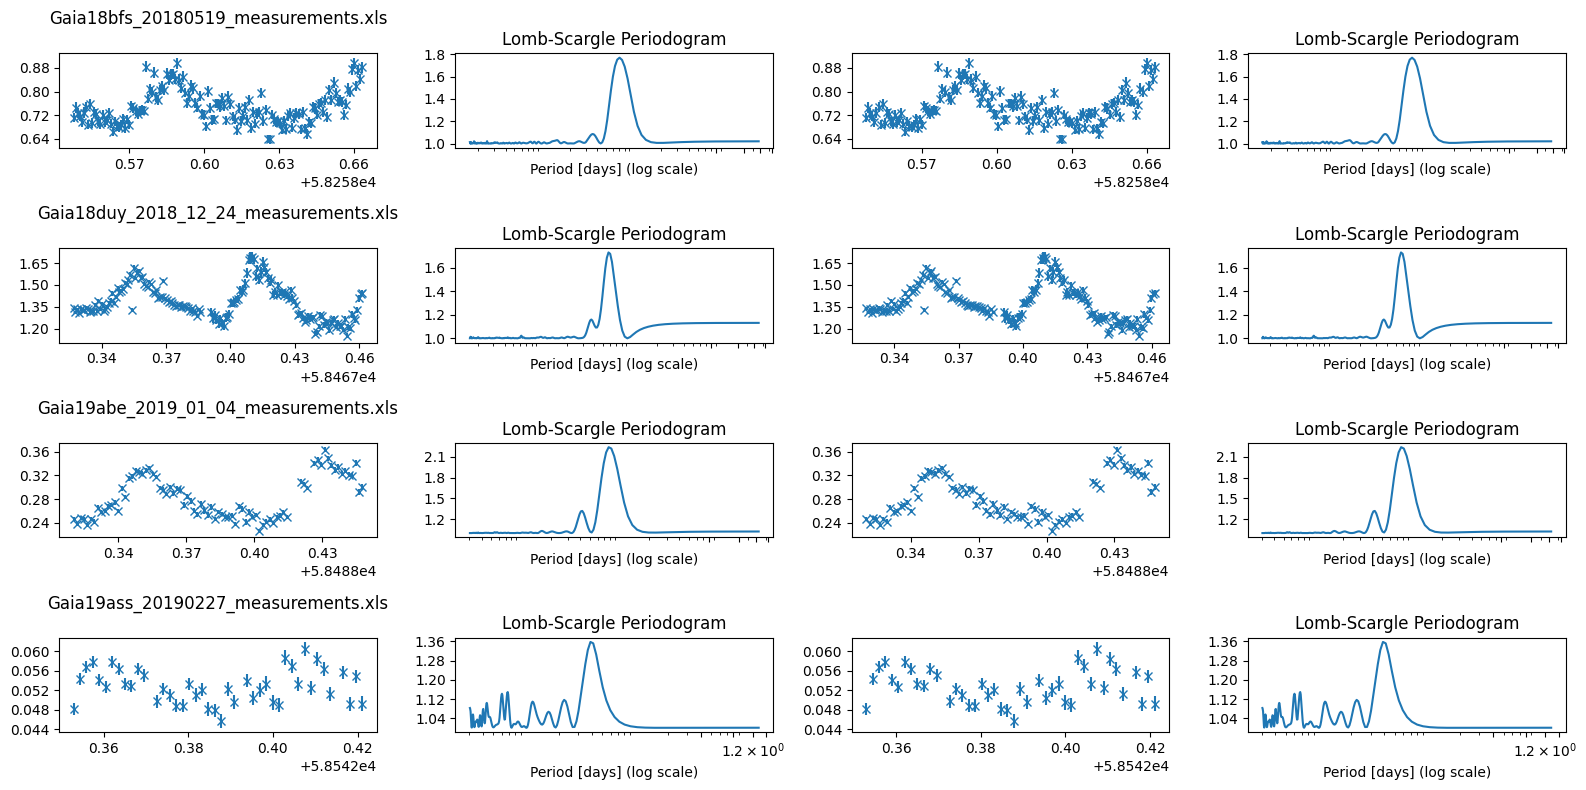

In [6]:
def multi_sine(t, *params):
    # offset = params[0]
    # params = params[1:]

    n_params = 4
    N = len(params) // n_params
    result = np.zeros_like(t)
    #result = np.full_like(t, offset)
    for i in range(N):
        offset = params[n_params*i + 0]
        A = params[n_params*i + 1]
        B = params[n_params*i + 2]
        f = params[n_params*i + 3]
        #print(offset, A,B,f)
        result += offset + A * np.sin(2 * np.pi *  f * t) + B * np.cos(2*np.pi * f * t)

    return result



# Directory filter for varying workspaces
REMOVE_CODING = False

files = glob.glob(r"..\**\*measurement*.xls", recursive = True)
files.extend(glob.glob(r"..\**\*measurement*.csv", recursive = True))

if REMOVE_CODING:
    files = list(filter(lambda s: not ("Coding" in s), files))

file_name_list = files

print("***PROGRAM START***\n")
print(f"{file_name_list = }")

results_list = []

for file in file_name_list:
    try:
        result = process_file(file, samples_per_peak = 10)
    except Exception as e:
        print(f"ERROR in {file = }. SKIPPING\n\n", e, "\n\n")
        continue
    results_list.append(result)

# n_periodograms = len(results_list)
#
# # Rel_flux vs time, periodogram, FAP, pvalue
# fig, ax_list = plt.subplots(nrows = n_periodograms, ncols = 4,
#                        figsize = (18, 8))
#
# # Iterating over multiple axes so needs to be a list
# if n_periodograms == 1:
#     ax_list = [ax_list]
#

#rows = "all"
#columns = "all"
rows = "all"##["18bfs", "19abe"]
columns = ["signal", "periodogram", "signal", "periodogram"]#["signal", "periodogram", "pvalue"]
n_xticks = 5
n_yticks = 5
bins = "blocks" # 15
n_bootstraps = 1000 # WARNING: For *ALL* periodogram false-alarm probabilities

double_bootstrap = 1
fig, ax_list, long_cache = plot_rows_columns(file_name_list, results_list,
                                                rows = rows,
                                                columns = columns,
                                                xticks = n_xticks,
                                                yticks = n_yticks,
                                                bins = bins,
                                                n_bootstraps = n_bootstraps,
                                                double_bootstrap = double_bootstrap
                                                )

if rows == "all":
    rows = list(range(len(file_name_list)))



n_sigma_conf = {1: 68.27/100, 2: 95.45/100, 3: 99.73/100, 4: 99.9937/100}


n_sigma = 3

conf_level = n_sigma_conf[n_sigma]

fap_threshold = 1e-4

ncpus = cpu_count() // 1
f_results = []

import dill
dill.settings['recurse'] = True
with pathos.multiprocessing.ProcessingPool(ncpus = ncpus) as pool:
    for (obj, axis) in enumerate(ax_list):
        if type(obj) == int:
            obj_name = file_name_list[obj]
        else:
            obj_name = obj
        print(f"STARTING {obj_name}")

        #print("\n\n\n", long_cache)
        (cache, ts, ls, target_id) = long_cache[rows[obj]]

        (freq_list, power_list) = cache["periodogram"]
        (time, flux, err_flux) = cache["signal"]

        n_peaks_remove = 3
        # Wrapper since lambda objects can't be pickled

        def p_f(nsigma):
            return calc_and_print_probability(
            ls, ts, target_id, freq_list, power_list,
            n_peaks = n_peaks_remove,
            double_bootstrap = double_bootstrap,
            fap_threshold = fap_threshold,
            n_sigma = nsigma
            )

        # Each element of res will be
        # (removed_freq, removed_power, removed_fap)
        res = pool.imap(p_f, range(3, 3+1))
        f_results.append(list(res))
        
        print("\n\n\n")
        # for n_sigma in range(2, 4+1):
        #
        #     conf_level = n_sigma_conf[n_sigma]
        #
        #     (ls, (freq_list, power_list), removed_values) = remove_max_power_freq(
        #             ls, freq_list, power_list, n = 4,
        #             n_bootstraps = n_bootstraps,
        #             double_bootstrap = double_bootstrap,
        #             snr = np.median(ts["Source_SNR_"+target_id]),
        #             conf_level = conf_level,
        #             fap_threshold = fap_threshold,
        #             )
        #
        #     #removed_values.append((power_freq, max_power, (data_fap_value, lower_conf, upper_conf)))
        #     removed_freq = u.Quantity([x[0] for x in removed_values])
        #     removed_power = [x[1] for x in removed_values]
        #
        #     # (data_fap_value, lower_conf, upper_conf)
        #     removed_fap = [x[2] for x in removed_values]
        #
        #     # try:
        #     #     len(removed_fap[0]) # test
        #     #     # Hope it's not a single eleent list...
        #     # except:
        #     #     removed_fap = [np.array(removed_fap)]
        #     # if type(removed_fap[0]) in [list, tuple]:
        #     #     for i in range(len(removed_fap)):
        #     #         removed_fap[i] = np.array(removed_fap[i])
        #     removed_fap = np.array(removed_fap)
        #     for (freq, (fap, lower_conf, upper_conf, pvalue)) in zip(removed_freq, removed_fap):
        #         period = (1/freq).to(u.min)
        #         fap_mean_p = fap.mean()*100
        #         (lower_conf_p, upper_conf_p) = (lower_conf * 100, upper_conf * 100)
        #         print(f"{period = }; {fap_mean_p = }% [{lower_conf_p} {upper_conf}]%; {pvalue = :}")
        #
        #     print("\n\n\n\n")
        #
        # continue
        # # Try to fit functions to periodogram to get uncertainty
        # # Get initial guess from lomb-scargle
        # initial_guess = []
        # bounds = []
        # for freq in removed_freq:
        #     model_params = ls.model_parameters(freq).value.tolist()
        #     offset, A, B = model_params
        #
        #     freq = freq.value
        #
        #     minutes_tol = 60
        #     day_tol = minutes_tol/60/24
        #     freq_bounds = [(freq-day_tol, freq+day_tol)]
        #     ab_bounds = [(offset - 0.5, offset + 0.5), (A-3, A+3), (B-3, B+3)]
        #
        #     ab_bounds.extend(freq_bounds)
        #
        #     bounds.append(ab_bounds)
        #     #print(f"{model_params = }")
        #     initial_guess.extend([offset, A,B,freq])
        #
        # print(f"{initial_guess = }")
        #
        # t = get_time_values(ls.t, "unix")
        # y = ls.y - np.mean(ls.y)
        #
        # flat_bounds = [[],[]]
        # for bounds_list in bounds:
        #     for param in bounds_list:
        #         flat_bounds[0].append(param[0])
        #         flat_bounds[1].append(param[1])
        # #bounds = np.array(bounds).flatten()
        #
        # popt, pcov = curve_fit(multi_sine, t, y, p0=initial_guess, bounds = flat_bounds)
        #
        # print(f"Stability: {np.linalg.cond(pcov) = }")
        # offset = popt[0]
        # offset_err = np.sqrt(pcov[0, 0])
        #
        # sine_params = popt[1:].reshape(-1, 3)
        # sine_uncertainties = np.sqrt(np.diag(pcov)[1:]).reshape(-1, 3)
        #
        # model_y = multi_sine(t, *sine_params)
        # print(model_y)
        # exit()
        # plt.plot(t, y)
        # plt.plot(t, model_y)
        # #print
        # plt.show()
        # # Frequency uncertainties
        # freq_params = sine_params[:,2] / u.day # (A,B,f)
        # freq_uncertainties = sine_uncertainties[:,2] / u.day
        #
        # # Values are in per day
        # period_params = (1/freq_params).to(u.min)
        # period_unc = (1/freq_uncertainties).to(u.min)
        #
        # for (period, unc) in zip(period_params, period_unc):
        #     print(f"{period = } +/ {unc}")
        # # print(f"{freq_params = }")
        # # print(f"{freq_uncertainties = }")
        #
        #
        # axis[1].cla() # wipe previous iteration
        # axis[1].plot(1/freq_list, power_list)
        # axis[1].set_xscale("log")
        # #axis[1].set_yscale("log")
        #
        # axis[2].cla() # wipe previous iteration
        # time = get_time_values(ts["time"], time_format = "unix")
        # #axis[2].errorbar(time, ls.y, yerr = ls.dy.value.tolist(), fmt = "x")
        # axis[2].plot(time, ls.y)
        #
        print("\n\n\n\n")
#plt.show()

Results for ..\Light Curves\Gaia18bfs\Gaia18bfs_20180519_measurements.xls
period = <Quantity 100.94606077 min>; fap_mean_p = 0.0% [0.0 0.0]%; pvalue = 0.0


[95.08776897]
Only one period found
0.05282973699134904 0.007367569995206998
Model flux: [0.06019731 0.06117613 0.06198727 0.06260721 0.06302335 0.06322764
 0.06321569 0.06298811 0.06254974 0.06190931 0.0610801  0.06007884
 0.05764662 0.05626834 0.05481652 0.05332468 0.05182338 0.05034332
 0.0489152  0.04756744 0.04632824 0.0452254  0.04428027 0.04351245
 0.04293787 0.04241534 0.04247746 0.04275488 0.04324179 0.04392862
 0.04480085 0.04583961 0.04702493 0.04833115 0.04972956 0.05119191
 0.05268953 0.05418876 0.05566092 0.05839732 0.05960657 0.06067499
 0.06158062]
0.05282973699134904 0.007367569995206998
Model flux: [0.06019731 0.06117613 0.06198727 0.06260721 0.06302335 0.06322764
 0.06321569 0.06298811 0.06254974 0.06190931 0.0610801  0.06007884
 0.05764662 0.05626834 0.05481652 0.05332468 0.05182338 0.05034332
 0.0489152  0.0475

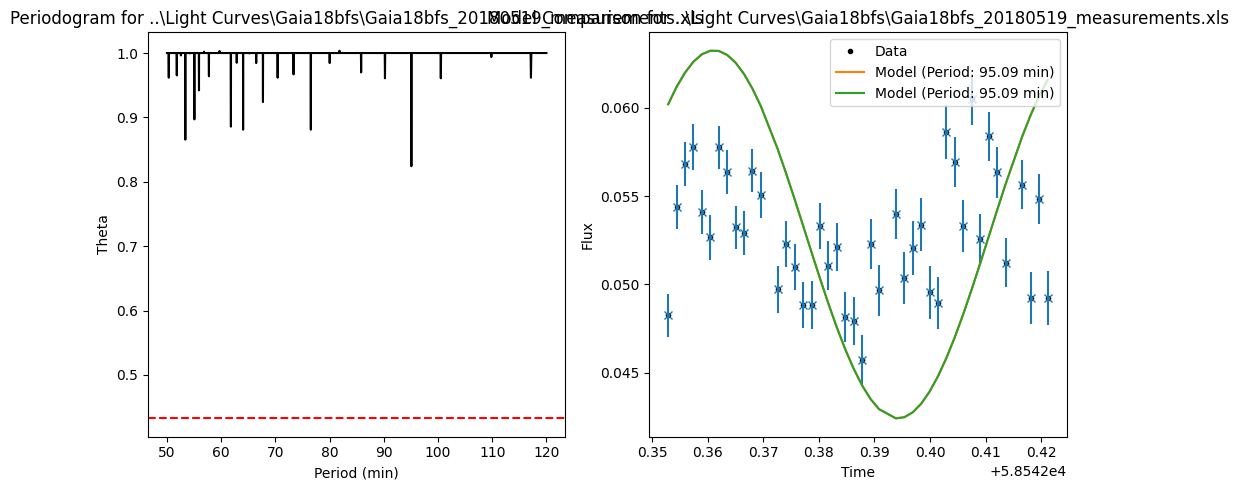

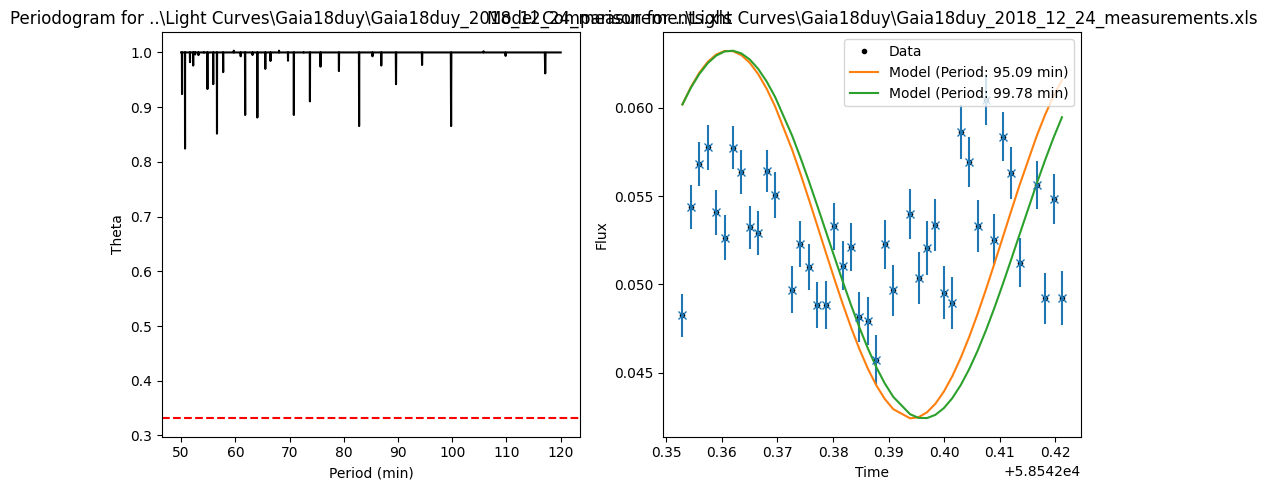

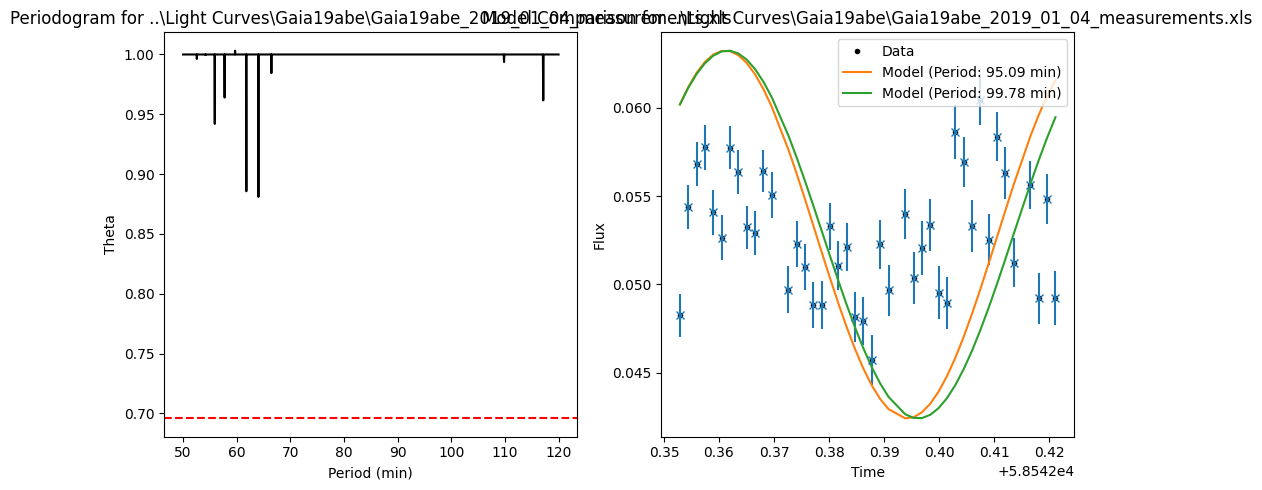

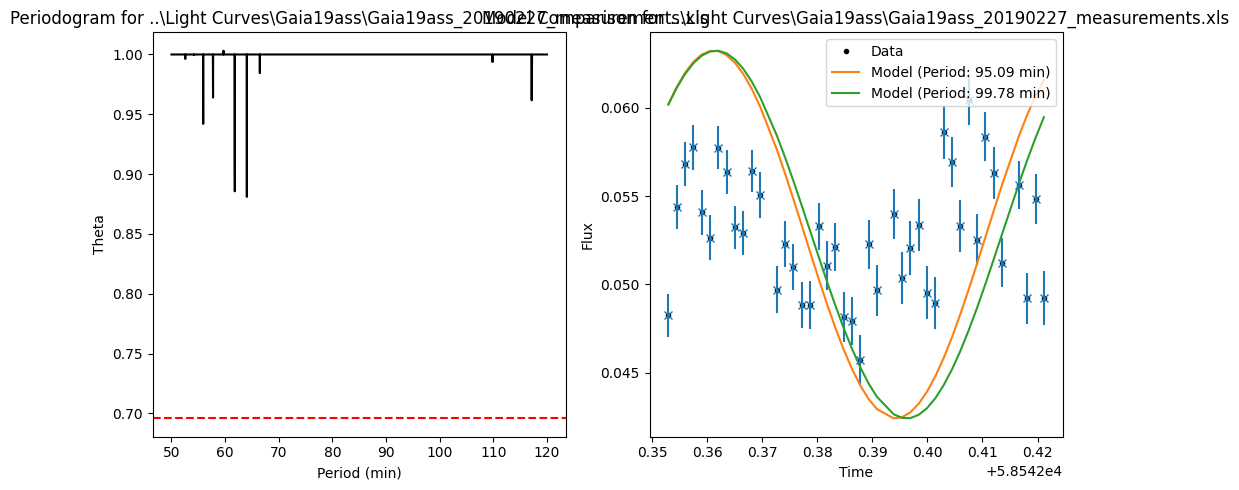

In [ ]:
possible_periods = [[]]*len(f_results)# List of periods for each object
for (idx, result) in enumerate(f_results, start = 0):
        smallest_n = len(result)+2 # n smallest theta values


        fig, ax = plt.subplots(1, 2, figsize=(10, 5))
        for axis in ax:
            axis.cla()
        print(f"Results for {file_name_list[idx]}")
        (removed_freq, removed_power, removed_fap) = result[0]
        for (freq, (fap, lower_conf, upper_conf, pvalue)) in zip(removed_freq, removed_fap):
            period = (1/freq).to(u.min)
            fap_mean_p = fap.mean()*100
            (lower_conf_p, upper_conf_p) = (lower_conf * 100, upper_conf * 100)
            print(f"{period = }; {fap_mean_p = }% [{lower_conf_p} {upper_conf_p}]%; {pvalue = }")


            # PDM analysis
            min_freq = 1/(50*u.min)
            max_freq = 1/(60*2*u.min)

            # min_freq = min_freq.to(1/u.day)
            # max_freq = max_freq.to(1/u.day)
            
            if max_freq.value < min_freq.value:
                max_freq, min_freq = min_freq, max_freq
                
                # old_min_freq = freq_list.min()
                # if min_freq.value > old_min_freq.value:
                #     min_freq = old_min_freq


            n_bins = 4*int(len(time)/freq.to(1/u.day).value)
            # print(f"Number of bins {n_bins}")
            # Oversampling
            n_freqs = 10*len(freq_list)#int(1e+5)#len(result) + 2 # wiggle room in pdm 
            #resolution = time[1]-time[0]
            num_data_points = len(time) 
            pdm_p = 1 - n_sigma_conf[n_sigma] # significance level
            assert 0 < pdm_p < 1, f"Invalid significance level {pdm_p}"
            sig_theta = beta_test(n = num_data_points, n_bins = n_bins, p = pdm_p)
            # print(f"Significant theta {sig_theta}")
            
            # Err Otherwise: "Convert to numpy array or Astrop Time object"
            pdm_time = np.array(time)
            pdm_flux = np.array(flux)
            pdm_err_flux = np.array(err_flux)
            pdm_freq, pdm_theta = pdm(
                pdm_time, pdm_flux, min_freq.value, max_freq.value, n_freqs, sigma=pdm_err_flux,
                n_bins=n_bins, verbose=1
            )
            # Find the best period
            
            smallest_n_theta = pdm_theta.argsort()[:smallest_n]
            best_freq = pdm_freq[smallest_n_theta]
            detected_periods = 1/best_freq

            possible_periods[idx].extend(detected_periods)
            # print(f"Detected periods: {1/best_freq}")

        # Plotting
        ax[0].plot(1/pdm_freq, pdm_theta, "k-")
        ax[0].set_xlabel("Period (min)")
        ax[0].set_ylabel("Theta")
        ax[0].set_title(f"Periodogram for {file_name_list[idx]}")
        # ax.set_yscale("log")

        # Plot significant theta value
        ax[0].axhline(sig_theta, color="red", linestyle="--", label="Significance level")
        print("\n")

        # Find possible periods
        # Know period should be above 70mins
        periods = np.array(possible_periods[idx])
        periods = np.unique(periods)
        periods = periods[periods > 77]
        
        print(periods)
        if len(periods) == 0:
            print("No valid periods found")
            continue
        elif len(periods) == 1:
            print("Only one period found")
            min_period = periods[0]
            min_period_next = periods[0]
        else:
            # Find closest two periods
            periods = np.sort(periods)
            diff = np.diff(periods)
            min_diff_idx = np.argmin(diff)
            min_diff = diff[min_diff_idx]
            min_period = periods[min_diff_idx]
            min_period_next = periods[min_diff_idx + 1]
            # print(f"Closest periods: {min_period}, {min_period_next} with difference {min_diff}")
            # print(f"Possible periods: {periods}")


        # Plotting models of each closest period compared to data
        ax[1].plot(time, flux, "k.", label="Data")
        ax[1].errorbar(time, flux, yerr=err_flux, fmt="x")

        # Fit model to data
        for period in [min_period, min_period_next]:
            freq = 1 / period
            
            mean = np.mean(flux)
            amplitude = (np.max(flux) - np.min(flux)) / 4

            print(mean, amplitude)

            new_time = np.array(time)
            new_time = new_time - np.min(new_time)
            freq = (freq /u.min).to(1/u.day).value
            model_flux = mean + amplitude * np.sin(2 * np.pi * freq * new_time) \
                + amplitude * np.cos(2 * np.pi * freq * new_time)
            print(f"Model flux: {model_flux}")

            ax[1].plot(time, model_flux, label=f"Model (Period: {period:.2f} min)")

        ax[1].set_xlabel("Time")
        ax[1].set_ylabel("Flux")
        ax[1].legend()
        ax[1].set_title(f"Model Comparison for {file_name_list[idx]}")



        fig.tight_layout()


plt.show()